Project root: C:\Users\shrut\heart-disease-mlops
(303, 14) (303, 14)
Shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


Missing values (raw):
ca      4
thal    2
dtype: int64
Duplicates: 0


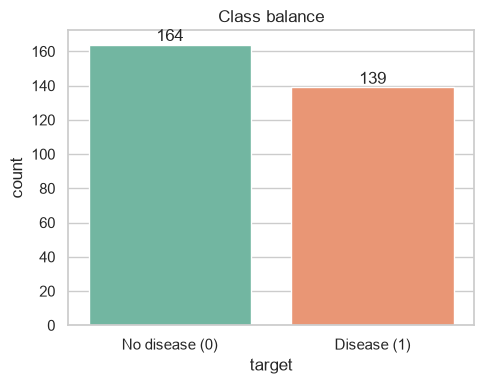

target
0    0.541
1    0.459
Name: proportion, dtype: float64


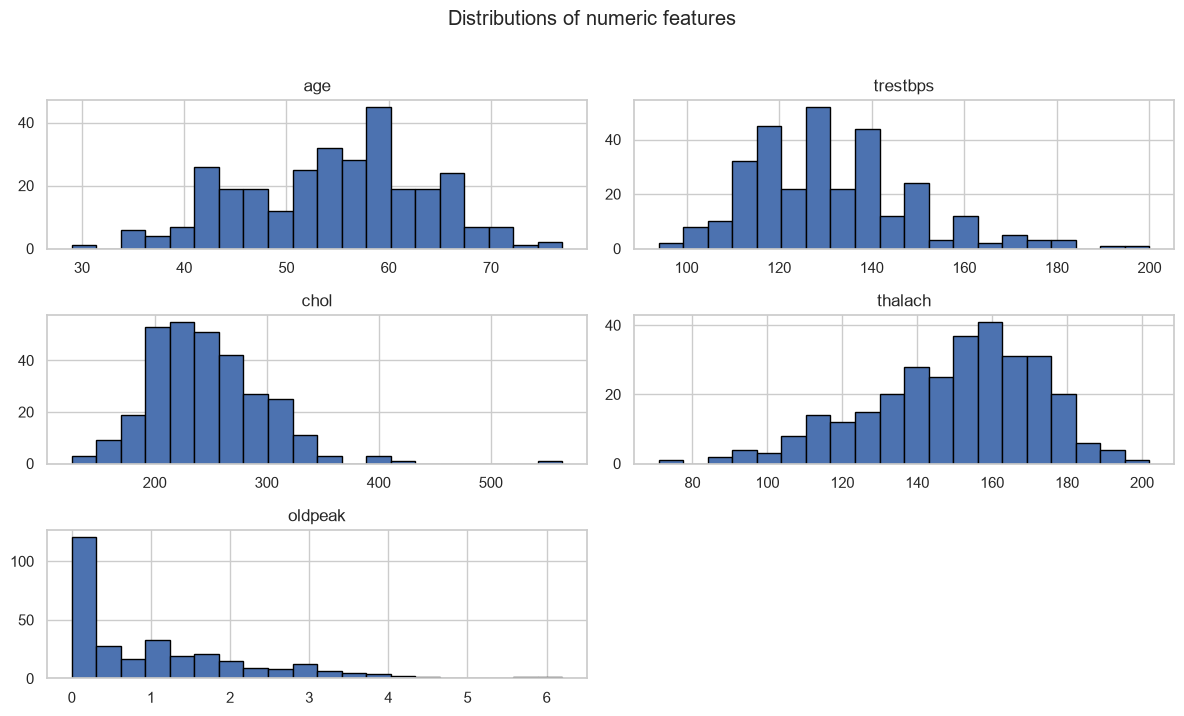

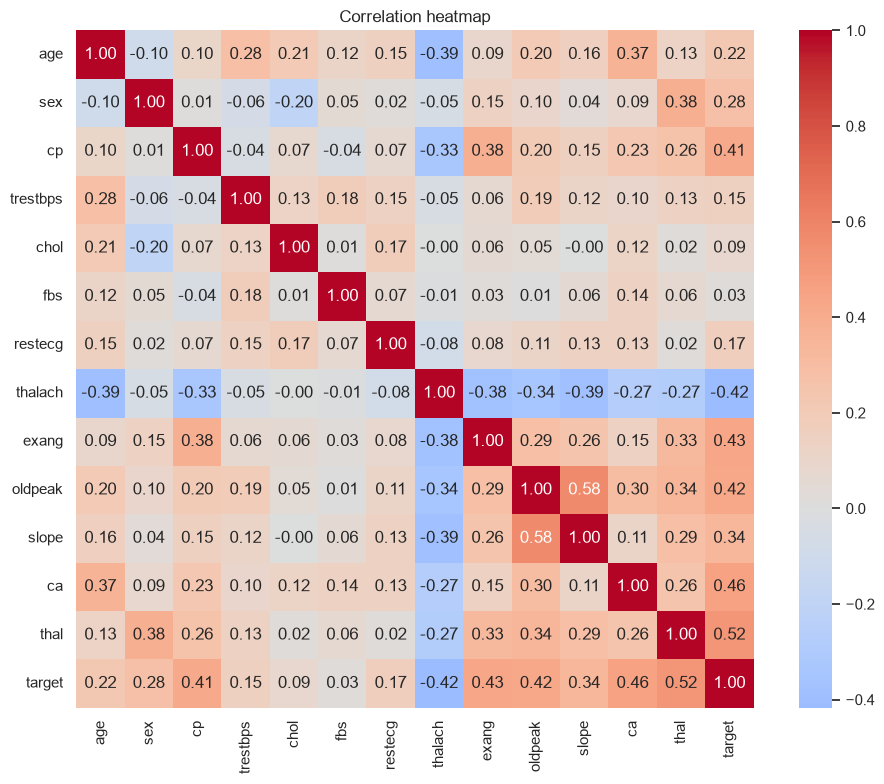

thal        0.522057
ca          0.460033
exang       0.431894
oldpeak     0.424510
cp          0.414446
slope       0.339213
sex         0.276816
age         0.223120
restecg     0.169202
trestbps    0.150825
chol        0.085164
fbs         0.025264
thalach    -0.417167
Name: target, dtype: float64


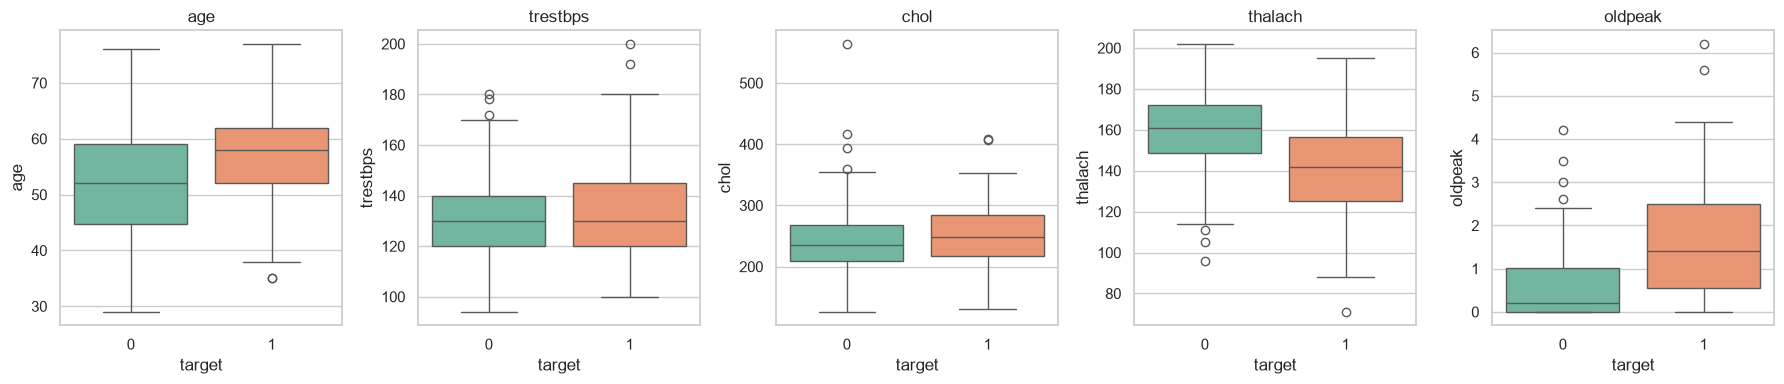

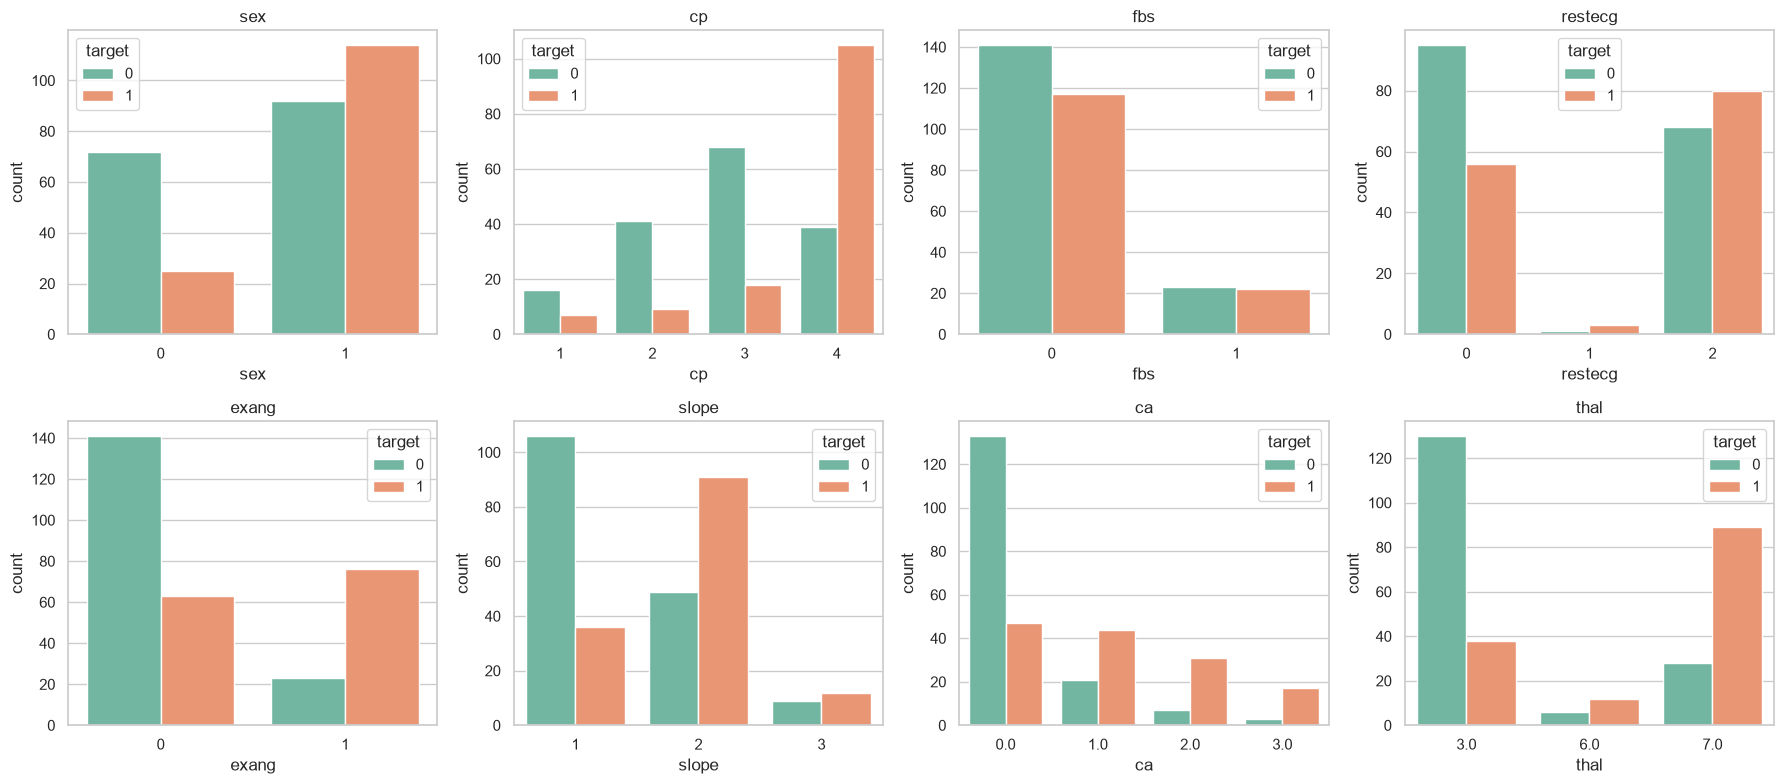

In [5]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

NUMERIC_FEATURES = ["age", "trestbps", "chol", "thalach", "oldpeak"]
CATEGORICAL_FEATURES = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]
TARGET = "target"

# find the project root (the folder that contains "data"), wherever the notebook runs
ROOT = Path(os.getcwd())
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

OUT = ROOT / "screenshots" / "eda"
OUT.mkdir(parents=True, exist_ok=True)

raw = pd.read_csv(ROOT / "data" / "raw" / "heart_raw.csv")
df = pd.read_csv(ROOT / "data" / "processed" / "heart_clean.csv")
print("Project root:", ROOT)
print(raw.shape, df.shape)

#overview
print("Shape:", raw.shape)
display(raw.head())
display(raw.describe().T)
print("Missing values (raw):")
print(raw.isna().sum()[raw.isna().sum() > 0])
print("Duplicates:", raw.duplicated().sum())

#class balance
fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(x=TARGET, data=df, hue=TARGET, palette="Set2", legend=False, ax=ax)
ax.set_xticks([0, 1])
ax.set_xticklabels(["No disease (0)", "Disease (1)"])
ax.set_title("Class balance")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.tight_layout()
plt.savefig(OUT / "class_balance.png", dpi=150)
plt.show()
print(df[TARGET].value_counts(normalize=True).round(3))

#histograms
df[NUMERIC_FEATURES].hist(bins=20, figsize=(12, 7), edgecolor="black")
plt.suptitle("Distributions of numeric features", y=1.02)
plt.tight_layout()
plt.savefig(OUT / "histograms.png", dpi=150)
plt.show()

#correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation heatmap")
plt.tight_layout()
plt.savefig(OUT / "correlation_heatmap.png", dpi=150)
plt.show()
print(df.corr()[TARGET].drop(TARGET).sort_values(ascending=False))

# numeric features by target
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, col in zip(axes, NUMERIC_FEATURES):
    sns.boxplot(x=TARGET, y=col, data=df, hue=TARGET, palette="Set2", legend=False, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.savefig(OUT / "boxplots_by_target.png", dpi=150)
plt.show()

#categorical features by target
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), CATEGORICAL_FEATURES):
    sns.countplot(x=col, hue=TARGET, data=df, palette="Set2", ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.savefig(OUT / "categorical_by_target.png", dpi=150)
plt.show()

